# Praktikum 05 — Studi Kasus Preeklamsia: Memahami dan Membersihkan Data

**Rangkaian:** *From Data to Machine Learning* · **Posisi:** Praktikum 05 dari 09  
**Kompetensi utama:** *data understanding, data quality assessment, deterministic cleaning, data provenance*  
**Dataset:** `dataKasus-1.xlsx` · Sheet `2022` · **561 baris, 13 kolom pada sumber**  
**Perkiraan durasi:** 100–130 menit (materi + latihan + pembahasan)

> **Penting:** Dataset dan pemetaan label ini dipakai untuk **latihan metode Machine Learning**, bukan untuk diagnosis, triase, atau keputusan klinis. Unit pasien, kronologi pengukuran, kualitas label dan validitas eksternal belum terverifikasi. **Jangan menganggap setiap baris mewakili pasien unik.**

**Batasan kurikulum:** Modul 05 memeriksa dan membersihkan data secara deterministik **tanpa imputasi dan tanpa training model**. Pemisahan train/test, imputasi statistik dan evaluasi dilaksanakan pada **Praktikum 06**.

## A. Peta belajar dan capaian pembelajaran

| Tahap | Kompetensi yang dipelajari | Bukti hasil |
|---|---|---|
| 1. Orientasi | Menentukan unit analisis, tujuan label, risiko leakage | Pernyataan tujuan dan batasan |
| 2. Memahami sumber | Memeriksa file, sheet, tipe data, kolom | Data dictionary awal |
| 3. Data quality assessment | Menghitung missing value, label, kategori, profil identik | Tabel audit + grafik |
| 4. Menetapkan skema | Memilah kolom fitur, target, identifier dan catatan | Skema fitur eksplisit |
| 5. Cleaning deterministik | Trim spasi, parsing usia dan paritas, target mapping | Matriks X, label y |
| 6. Validasi & ekspor | Memastikan tidak ada baris/label hilang diam-diam | CSV + laporan audit |
| 7. Evaluasi pembelajaran | Menjawab konsep, latihan dan tantangan | Kunci jawaban lengkap |

**Prasyarat:** Praktikum 01 (EDA), 02 (feature space), dan 03 (data preprocessing). Di sini kita **menerapkan audit pada kasus nyata**, bukan mengulang detail teknik imputasi/scaling dari Modul 03.

## B. Landasan teori singkat

**Data understanding** bertujuan memahami asal, arti, cakupan dan batasan setiap variabel sebelum membuat model. **Data cleaning** bertujuan memperbaiki masalah format yang dapat dipastikan, sambil menjaga data sumber dapat ditelusuri.

Perhatikan perbedaan berikut:

- **Kesalahan format yang aman dibetulkan:** `'PE '` menjadi `'PE'`; `'34 TH'` menjadi `34.0` melalui aturan yang terdokumentasi.
- **Keputusan berbasis asumsi yang perlu persetujuan:** menghapus baris karena usia ekstrem, menyamakan profil identik dengan pasien yang sama, atau menggabungkan label klinis tanpa definisi.
- **Imputasi berbasis statistik:** belum dilakukan pada Modul 05. Nilai median/modus harus dihitung dari training saja saat Praktikum 06.

**Target pembelajaran:** klasifikasi biner `Non PE = 0` dan kelompok PE = `1` sesuai pemetaan yang ada dalam paket sumber; penggabungan subkategori **bukan** bukti kesetaraan klinis.

## C. Menyiapkan lingkungan dan mencari file secara otomatis

Notebook dapat digunakan di folder paket lengkap atau langsung dari folder ZIP mandiri. Jalankan berurutan dari atas (Kernel → Restart & Run All). File Excel dan helper tersedia di `studi_kasus/data/asli/` dan `studi_kasus/python/`.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': 0.2})

# Mendukung ZIP mandiri maupun paket workshop asli (termasuk notebook dalam subfolder).
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'studi_kasus/data/asli/dataKasus-1.xlsx').exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        'File studi_kasus/data/asli/dataKasus-1.xlsx tidak ditemukan. '
        'Ekstrak ZIP lengkap, lalu jalankan notebook di dalam folder hasil ekstrak.'
    )
CASE = ROOT / 'studi_kasus'
DATA_PATH = CASE / 'data/asli/dataKasus-1.xlsx'
OUT = CASE / 'data/hasil'
OUT.mkdir(parents=True, exist_ok=True)
print('Folder proyek:', ROOT)
print('Sumber data:', DATA_PATH.relative_to(ROOT))
print('Pandas:', pd.__version__)

Folder proyek: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/final_release/Workshop_From_Data_to_ML
Sumber data: studi_kasus/data/asli/dataKasus-1.xlsx
Pandas: 2.3.1


### C1. Pastikan struktur workbook dan sheet

Memeriksa file sebelum membaca membantu mencegah penggunaan sheet yang salah. Pada paket asli, sheet utama bernama **`2022`**.

In [2]:
xls = pd.ExcelFile(DATA_PATH)
print('Sheet tersedia:', xls.sheet_names)
assert '2022' in xls.sheet_names, 'Sheet 2022 tidak ditemukan; periksa sumber data.'
raw = pd.read_excel(DATA_PATH, sheet_name='2022')
print('Ukuran raw data (baris, kolom):', raw.shape)
print('Nama kolom:', raw.columns.tolist())
assert raw.shape == (561, 13), 'Sumber berbeda dari paket yang diaudit; periksa sebelum lanjut.'

Sheet tersedia: ['2022']
Ukuran raw data (baris, kolom): (561, 13)
Nama kolom: ['NO', 'NAMA', 'USIA', 'PARITAS', 'JARAK KELAHIRAN', 'RIW HIPERTENSI', 'RIW PE', 'OBESITAS', 'RIW DM', 'RIW HIPERTENSI/PE DALAM KELUARGA', 'SOSEK RENDAH', 'PE/Non PE', 'Unnamed: 12']


### C2. Pratinjau aman: tanpa kolom pengenal langsung

`NO`, `NAMA`, dan catatan bebas **tidak ditampilkan** dalam pratinjau. Nama pada paket workshop berupa placeholder, tetapi itu tidak membuktikan independensi pasien. Data sumber tetap dipertahankan; hasil analisis hanya menggunakan kolom yang relevan.

In [3]:
ID_COLS = ['NO', 'NAMA']
NOTES_COLS = ['Unnamed: 12']
print('5 record pertama (tanpa pengenal/catatan):')
display(raw.drop(columns=ID_COLS + NOTES_COLS, errors='ignore').head())
print('5 record terakhir:')
display(raw.drop(columns=ID_COLS + NOTES_COLS, errors='ignore').tail())

5 record pertama (tanpa pengenal/catatan):


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,RIW PE,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH,PE/Non PE
0,23 TH,3,< 2 tahun,Tidak,Tidak,Tidak,Ya,Tidak,>UMR,Non PE
1,29 TH,2,< 2 tahun,Tidak,PEB,Tidak,Tidak,Ada,>UMR,PE
2,20 TH,1,anak pertama,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE
3,18 TH,1,anak pertama,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE
4,34 TH,3,> 2 tahun,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE


5 record terakhir:


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,RIW PE,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH,PE/Non PE
556,40 TH,3,> 2 tahun,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE
557,28 TH,3,< 2 tahun,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE
558,41 TH,3,> 2 tahun,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE
559,32 TH,2,> 2 tahun,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE
560,30 TH,2,> 2 tahun,Tidak,Tidak,Tidak,Tidak,Tidak,>UMR,Non PE


## D. Menetapkan unit analisis dan peran setiap kolom

**Satu baris = satu *record* data.** Jangan menyebutnya satu pasien secara otomatis. Tidak tersedia pengenal pasien tervalidasi yang memungkinkan audit pasien berulang atau pemisahan antarpasien.

| Kolom | Peran dalam latihan | Keputusan |
|---|---|---|
| `NO`, `NAMA` | Pengenal/penomoran | Dikecualikan dari model |
| `PE/Non PE` | Label/outcome asli | Dipetakan ke target biner, aturan dicatat |
| `RIW PE` | Informasi riwayat yang definisi dan waktunya belum jelas | Dipertahankan untuk audit, **tidak dipakai** sebagai fitur utama |
| `Unnamed: 12` | Catatan bebas | Dipertahankan pada sumber, dikecualikan dari model |
| `USIA`, `PARITAS` | Fitur numerik | Dikoreksi format bila valid |
| Enam kolom lainnya | Fitur kategori | Trim spasi dan pertahankan kategori aslinya |

**Delapan fitur utama** sesuai `pe_workflow.py` akan digunakan kembali pada Praktikum 06–08.

In [4]:
NUM = ['USIA', 'PARITAS']
CAT = [
    'JARAK KELAHIRAN', 'RIW HIPERTENSI', 'OBESITAS', 'RIW DM',
    'RIW HIPERTENSI/PE DALAM KELUARGA', 'SOSEK RENDAH'
]
FEATURES = NUM + CAT
TARGET_COL = 'PE/Non PE'
TARGET_MAP = {
    'Non PE': 0, 'PE': 1, 'PEB': 1, 'Eklamsia': 1,
    'PE gemelli': 1, 'PEB impending eklampsi': 1
}
required = FEATURES + [TARGET_COL, 'RIW PE']
missing_required = [c for c in required if c not in raw.columns]
assert not missing_required, f'Kolom wajib tidak ditemukan: {missing_required}'

role_table = pd.DataFrame([
    *[{'kolom': c, 'peran': 'prediktor numerik'} for c in NUM],
    *[{'kolom': c, 'peran': 'prediktor kategorikal'} for c in CAT],
    {'kolom': TARGET_COL, 'peran': 'target asli'},
    {'kolom': 'RIW PE', 'peran': 'audit saja — tidak dipakai sebagai prediktor'},
    {'kolom': 'NO', 'peran': 'identifier — dikecualikan'},
    {'kolom': 'NAMA', 'peran': 'identifier — dikecualikan'},
    {'kolom': 'Unnamed: 12', 'peran': 'catatan — dikecualikan'},
])
display(role_table)
print('Total prediktor:', len(FEATURES))

,kolom,peran
0,USIA,prediktor numerik
1,PARITAS,prediktor numerik
2,JARAK KELAHIRAN,prediktor kategorikal
3,RIW HIPERTENSI,prediktor kategorikal
4,OBESITAS,prediktor kategorikal
5,RIW DM,prediktor kategorikal
6,RIW HIPERTENSI/PE DALAM KELUARGA,prediktor kategorikal
7,SOSEK RENDAH,prediktor kategorikal
8,PE/Non PE,target asli
9,RIW PE,audit saja — tidak dipakai sebagai prediktor


Total prediktor: 8


## E. Audit kualitas data sebelum cleaning

Mulai dari kondisi aslinya. Jangan langsung mengganti nilai kosong, menghapus duplikat, atau membuang kategori yang tidak umum. Sebagian temuan merupakan **pertanyaan untuk pemilik data**, bukan kesalahan otomatis.

### E1. Tipe data dan persentase missing value

In [5]:
quality = pd.DataFrame({
    'dtype_asli': raw.dtypes.astype(str),
    'jumlah_missing': raw.isna().sum(),
    'missing_persen': (raw.isna().mean() * 100).round(2),
    'unique_non_null': raw.nunique(dropna=True)
})
display(quality)
print('Total nilai kosong di seluruh tabel:', int(raw.isna().sum().sum()))

,dtype_asli,jumlah_missing,missing_persen,unique_non_null
NO,int64,0,0.00,561
NAMA,object,0,0.00,561
USIA,object,3,0.53,72
PARITAS,int64,0,0.00,7
JARAK KELAHIRAN,object,7,1.25,4
RIW HIPERTENSI,object,0,0.00,2
RIW PE,object,0,0.00,11
OBESITAS,object,0,0.00,2
RIW DM,object,0,0.00,2
RIW HIPERTENSI/PE DALAM KELUARGA,object,0,0.00,2


Total nilai kosong di seluruh tabel: 560


Catatan: `Unnamed: 12` hampir seluruhnya kosong karena berfungsi sebagai catatan tambahan. **Jangan melakukan imputasi** pada kolom ini hanya karena persentase kosongnya tinggi. Data tersebut memang tidak dijadikan fitur utama.

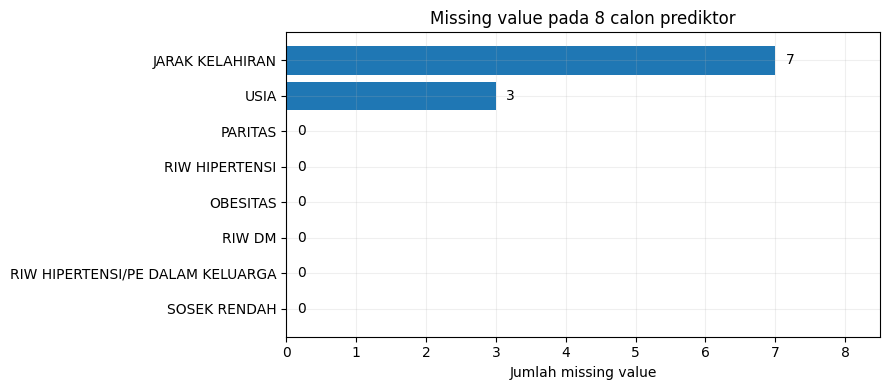

In [6]:
features_quality = quality.loc[FEATURES].sort_values('jumlah_missing', ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(features_quality.index, features_quality['jumlah_missing'])
ax.set(xlabel='Jumlah missing value', title='Missing value pada 8 calon prediktor')
ax.invert_yaxis()
for j, val in enumerate(features_quality['jumlah_missing']):
    ax.text(val + 0.15, j, str(int(val)), va='center')
ax.set_xlim(0, max(8, features_quality['jumlah_missing'].max() + 1.5))
plt.tight_layout(); plt.show()

### E2. Distribusi label sumber (sebelum digabung)

Tampilkan semua variasi label, termasuk subkategori PE. Jangan menganggap `PEB`, `Eklamsia`, dan label lain sebagai istilah klinis yang setara. Untuk tujuan **latihan**, label digabung melalui tabel yang terdokumentasi.

In [7]:
labels_raw = raw[TARGET_COL].astype('string').str.strip().replace('', pd.NA)
label_counts = labels_raw.value_counts(dropna=False).rename_axis('label_asli').reset_index(name='jumlah')
display(label_counts)
print('Jumlah label kosong:', int(labels_raw.isna().sum()))
print('Label yang tidak tercantum dalam mapping:', sorted(set(labels_raw.dropna()) - set(TARGET_MAP)))

,label_asli,jumlah
0,Non PE,520
1,PEB,20
2,PE,18
3,Eklamsia,1
4,PE gemelli,1
5,PEB impending eklampsi,1


Jumlah label kosong: 0
Label yang tidak tercantum dalam mapping: []


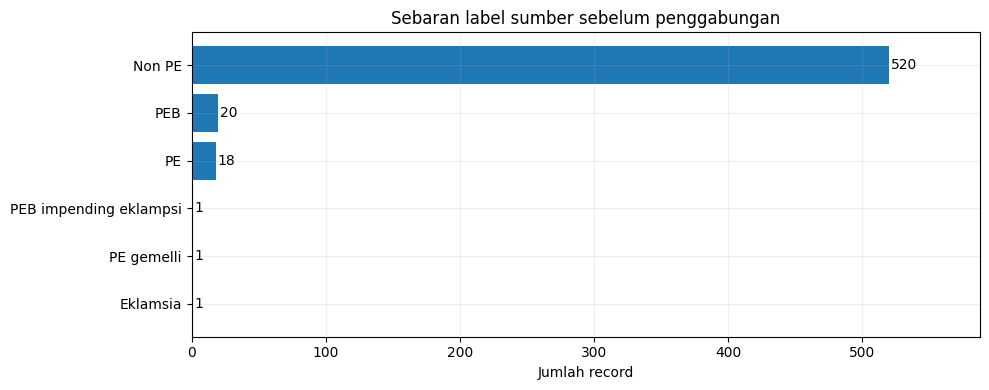

In [8]:
plt.figure(figsize=(10, 4))
plot_counts = labels_raw.value_counts().sort_values()
plt.barh(plot_counts.index, plot_counts.values)
plt.xlabel('Jumlah record'); plt.title('Sebaran label sumber sebelum penggabungan')
for i, v in enumerate(plot_counts.values):
    plt.text(v + 1, i, str(v), va='center')
plt.xlim(0, plot_counts.max() * 1.13)
plt.tight_layout(); plt.show()

### E3. Audit variasi kategori dan masalah whitespace

Contoh: `'> 2 tahun '` dan `'> 2 tahun'` diperlakukan sebagai dua nilai kategori sebelum `str.strip()`. Perbaikan ini deterministik karena hanya menghapus spasi di awal/akhir, bukan mengubah makna.

In [9]:
for col in CAT + ['RIW PE']:
    vals = raw[col].astype('string')
    print(f'\n{col} | distinct sebelum trim={vals.nunique(dropna=True)}, sesudah={vals.str.strip().nunique(dropna=True)}')
    print(vals.str.strip().value_counts(dropna=False).head(12).to_dict())


JARAK KELAHIRAN | distinct sebelum trim=4, sesudah=3
{'anak pertama': 260, '> 2 tahun': 213, '< 2 tahun': 81, <NA>: 7}

RIW HIPERTENSI | distinct sebelum trim=2, sesudah=2
{'Tidak': 508, 'Ya': 53}

OBESITAS | distinct sebelum trim=2, sesudah=2
{'Tidak': 556, 'Ya': 5}

RIW DM | distinct sebelum trim=2, sesudah=2
{'Tidak': 556, 'Ya': 5}

RIW HIPERTENSI/PE DALAM KELUARGA | distinct sebelum trim=2, sesudah=2
{'Tidak': 550, 'Ada': 11}

SOSEK RENDAH | distinct sebelum trim=2, sesudah=2
{'>UMR': 557, '<UMR': 4}

RIW PE | distinct sebelum trim=11, sesudah=11
{'Tidak': 526, 'PEB': 19, 'PE': 6, 'HELLP SYNDROM': 2, 'Impending PE': 2, 'Impending Eklamsia': 1, 'Kejang Konvulsi': 1, 'impending eklamsia': 1, 'PE, HELLP Syndrome': 1, 'PEB impending eklampsi': 1, 'Impending Ekalmsia': 1}


### E4. Nilai usia dan paritas sebelum parsing

Untuk kolom `USIA` pada sumber terdapat nilai seperti `23 TH`, `22 th` dan nilai kosong. Kita memakai aturan eksplisit **mengambil kelompok digit pertama** dari string usia, lalu mengubahnya menjadi angka. Format ambigu harus ditinjau, bukan ditebak.

In [10]:
preview_usia = pd.DataFrame({'usia_asli': raw['USIA'].astype('string')})
preview_usia['usia_trim'] = preview_usia['usia_asli'].str.strip()
preview_usia['usia_angka'] = pd.to_numeric(
    preview_usia['usia_trim'].str.extract(r'(\d+)', expand=False), errors='coerce'
)
display(preview_usia.drop_duplicates().head(16))
print('Usia gagal terurai / kosong:', int(preview_usia['usia_angka'].isna().sum()))
print('Rentang hasil parsing:', (preview_usia['usia_angka'].min(), preview_usia['usia_angka'].max()))

,usia_asli,usia_trim,usia_angka
0,23 TH,23 TH,23
1,29 TH,29 TH,29
2,20 TH,20 TH,20
3,18 TH,18 TH,18
4,34 TH,34 TH,34
5,28 TH,28 TH,28
6,36 TH,36 TH,36
8,39 TH,39 TH,39
9,37 TH,37 TH,37
10,16,16,16


Usia gagal terurai / kosong: 3
Rentang hasil parsing: (np.int64(13), np.int64(43))


**Catatan QA:** usia 13–14 muncul dalam data dan perlu verifikasi kualitas sumber secara terpisah. Tidak ada ambang batas usia yang digunakan untuk menghapus baris dalam latihan ini. Nilai usia tidak boleh diasumsikan keliru hanya karena tidak lazim.

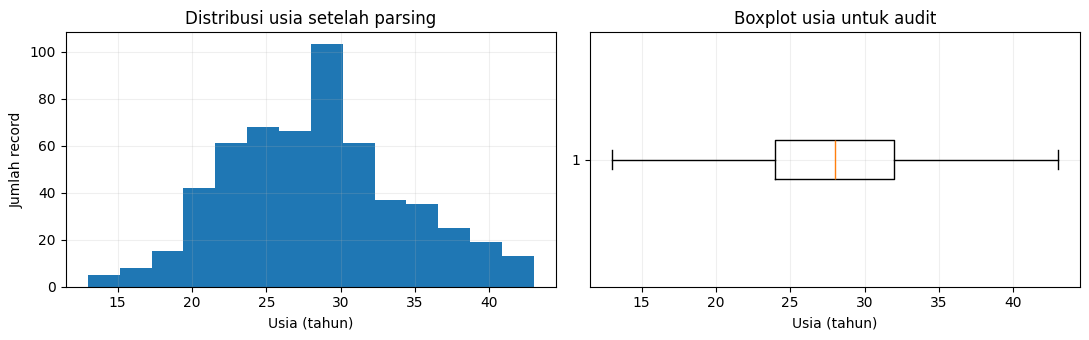

Jumlah record usia < 15 tahun (perlu telaah): 2


In [11]:
usia_numeric = preview_usia['usia_angka']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(usia_numeric.dropna(), bins=14)
axes[0].set(title='Distribusi usia setelah parsing', xlabel='Usia (tahun)', ylabel='Jumlah record')
axes[1].boxplot(usia_numeric.dropna(), vert=False)
axes[1].set(title='Boxplot usia untuk audit', xlabel='Usia (tahun)')
plt.tight_layout(); plt.show()
print('Jumlah record usia < 15 tahun (perlu telaah):', int((usia_numeric < 15).sum()))

### E5. Profil fitur yang identik ≠ pasien yang sama

Kombinasi delapan prediktor yang sama dapat ditemukan pada lebih dari satu record. Tanpa identifier pasien yang valid, ini **bukan** dasar untuk melakukan deduplikasi. Menghapusnya dapat mengubah proporsi kelas secara tidak beralasan.

In [12]:
raw_features = raw[FEATURES].copy()
identical_feature_profiles = int(raw_features.duplicated().sum())
raw_no_identifiers = raw.drop(columns=['NO', 'NAMA'], errors='ignore')
identical_except_identifiers = int(raw_no_identifiers.duplicated().sum())
print('Jumlah baris dengan fitur identik terhadap baris sebelumnya:', identical_feature_profiles)
print('Jumlah baris identik setelah identifier dikeluarkan:', identical_except_identifiers)
print('Tidak ada baris yang dihapus pada tahap ini.')

Jumlah baris dengan fitur identik terhadap baris sebelumnya: 299
Jumlah baris identik setelah identifier dikeluarkan: 283
Tidak ada baris yang dihapus pada tahap ini.


## F. Cleaning deterministik yang dapat diaudit

**Aturan:**

1. Merapikan whitespace pada nama kolom dan string kategori.
2. Mengganti string kosong menjadi missing value.
3. Mem-parse `USIA` dengan ekspresi reguler yang sama seperti paket sumber.
4. Mengubah `PARITAS` menjadi numerik tanpa imputasi.
5. Memvalidasi semua label lalu memetakan target biner.
6. Memilih delapan fitur yang telah ditetapkan tanpa identifier dan tanpa `RIW PE`.
7. **Mempertahankan seluruh 561 baris** kecuali ditemukan kegagalan validasi (yang menghentikan proses dan menuntut penelaahan).

### F1. Normalisasi format string (tanpa mengubah kategori substansial)

In [13]:
normalized = raw.copy()
normalized.columns = normalized.columns.str.strip()
for col in normalized.select_dtypes(include='object').columns:
    normalized[col] = (
        normalized[col].astype('string').str.strip().replace('', pd.NA)
    )

print('Sebelum: variasi JARAK KELAHIRAN =', raw['JARAK KELAHIRAN'].nunique(dropna=True))
print('Sesudah: variasi JARAK KELAHIRAN =', normalized['JARAK KELAHIRAN'].nunique(dropna=True))
print('Banyak record tetap:', len(normalized))

Sebelum: variasi JARAK KELAHIRAN = 4
Sesudah: variasi JARAK KELAHIRAN = 3
Banyak record tetap: 561


### F2. Parsing fitur numerik dan penetapan kategori

Pemilihan fitur harus konsisten dengan `pe_workflow.py` agar hasil Modul 05 dapat dipakai ulang pada Modul 06–08.

In [14]:
normalized['USIA'] = pd.to_numeric(
    normalized['USIA'].astype('string').str.extract(r'(\d+)', expand=False),
    errors='coerce'
).astype(float)
normalized['PARITAS'] = pd.to_numeric(normalized['PARITAS'], errors='coerce').astype(float)

X = normalized[FEATURES].copy()
for col in CAT:
    X[col] = X[col].astype(object).where(X[col].notna(), np.nan)

print('Bentuk feature matrix X:', X.shape)
print('Missing per fitur setelah parsing:')
display(X.isna().sum().to_frame('jumlah_missing'))
print('Dua fitur numerik:')
display(X[NUM].describe())

Bentuk feature matrix X: (561, 8)
Missing per fitur setelah parsing:


,jumlah_missing
USIA,3
PARITAS,0
JARAK KELAHIRAN,7
RIW HIPERTENSI,0
OBESITAS,0
RIW DM,0
RIW HIPERTENSI/PE DALAM KELUARGA,0
SOSEK RENDAH,0


Dua fitur numerik:


,USIA,PARITAS
count,558.000000,561.000000
mean,28.154122,1.709447
std,5.923926,1.012105
min,13.000000,0.000000
25%,24.000000,1.000000
50%,28.000000,2.000000
75%,32.000000,2.000000
max,43.000000,6.000000


### F3. Validasi pemetaan target sebelum konversi

Pemetaan mengikuti `TARGET_MAP` pada `pe_workflow.py` dalam paket sumber. Penggabungan dilakukan demi **tugas klasifikasi biner latihan**; definisi operasional label harus ditinjau sebelum penelitian atau pemakaian klinis.

In [15]:
original_labels = normalized[TARGET_COL]
unknown_labels = sorted(set(original_labels.dropna()) - set(TARGET_MAP))
if original_labels.isna().any() or unknown_labels:
    raise ValueError(
        f'Label kosong={int(original_labels.isna().sum())}; label asing={unknown_labels}. '
        'Periksa anotasi sumber; jangan mengubahnya otomatis.'
    )

y = original_labels.map(TARGET_MAP).astype(int).rename('target_PE')
map_table = pd.DataFrame([
    {'label_asli': name, 'target_PE': val,
     'jumlah_sumber': int((original_labels == name).sum())}
    for name, val in TARGET_MAP.items()
])
display(map_table)
print('Distribusi target akhir:', y.value_counts().sort_index().to_dict())
assert len(X) == len(y) == len(raw), 'Ada perubahan jumlah baris yang tak terduga.'

,label_asli,target_PE,jumlah_sumber
0,Non PE,0,520
1,PE,1,18
2,PEB,1,20
3,Eklamsia,1,1
4,PE gemelli,1,1
5,PEB impending eklampsi,1,1


Distribusi target akhir: {0: 520, 1: 41}


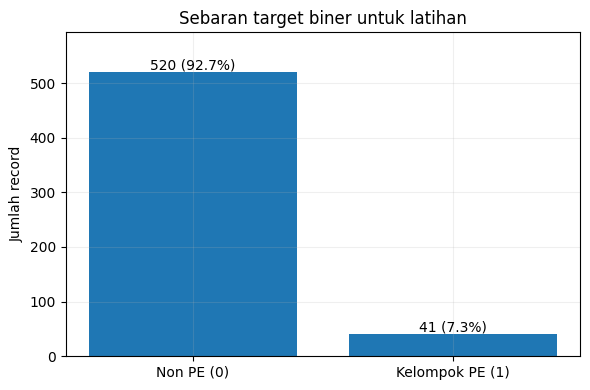

In [16]:
class_counts = y.value_counts().reindex([0,1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Non PE (0)', 'Kelompok PE (1)'], class_counts.values)
for i, value in enumerate(class_counts.values):
    ax.text(i, value + 5, f'{value} ({100*value/len(y):.1f}%)', ha='center')
ax.set_ylim(0, max(class_counts)*1.14)
ax.set(ylabel='Jumlah record', title='Sebaran target biner untuk latihan')
plt.tight_layout(); plt.show()

## G. Analisis deskriptif setelah cleaning

Analisis ini **deskriptif**, bukan untuk menyimpulkan penyebab risiko PE. Perbandingan kelas dapat terpengaruh kualitas label, seleksi sampel, dan waktu pengukuran fitur. Plot tidak membuktikan hubungan kausal.

### G1. Ringkasan numerik menurut target

In [17]:
clean = X.copy()
clean['target_PE'] = y
numeric_profile = clean.groupby('target_PE')[NUM].agg(['count','mean','median','min','max'])
display(numeric_profile.round(2))

USIA                           PARITAS                       
          count   mean median   min   max   count  mean median  min  max
target_PE                                                               
0           517  28.07   28.0  13.0  43.0     520  1.72    2.0  0.0  6.0
1            41  29.22   29.0  20.0  43.0      41  1.63    1.0  0.0  4.0

### G2. Tabulasi silang satu fitur kategorikal

Tabulasi silang hanya menggambarkan frekuensi, dan kategori langka berpotensi menghasilkan rasio yang tidak stabil.

In [18]:
ct = pd.crosstab(clean['RIW HIPERTENSI'], clean['target_PE'], dropna=False)
ct.columns = ['Non PE', 'Kelompok PE']
display(ct)
print('Proporsi per kategori (%):')
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

,Non PE,Kelompok PE
RIW HIPERTENSI,,
Tidak,492,16
Ya,28,25


Proporsi per kategori (%):


,Non PE,Kelompok PE
RIW HIPERTENSI,,
Tidak,96.9,3.1
Ya,52.8,47.2


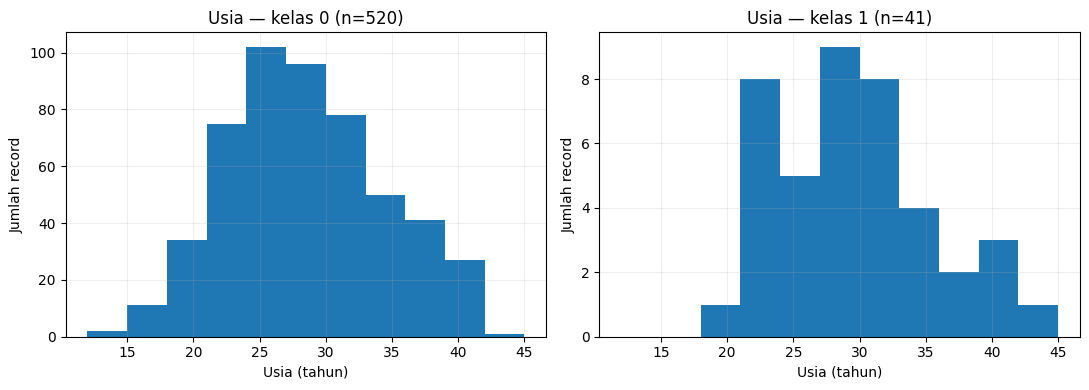

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, subset, ax in [(0, X.loc[y == 0], axes[0]), (1, X.loc[y == 1], axes[1])]:
    ax.hist(subset['USIA'].dropna(), bins=np.arange(12,46,3))
    ax.set(title=f'Usia — kelas {label} (n={(y == label).sum()})', xlabel='Usia (tahun)', ylabel='Jumlah record')
plt.tight_layout(); plt.show()

### G3. Pemeriksaan nilai kosong menurut target

Perbedaan pola missing antarlabel dapat menjadi sinyal kualitas data. **Jangan mengisi atau membuang baris** hanya dari tabel di bawah.

In [20]:
missing_by_target = X.isna().groupby(y).sum()
missing_by_target.index = ['Non PE', 'Kelompok PE']
display(missing_by_target.T)

,Non PE,Kelompok PE
USIA,3,0
PARITAS,0,0
JARAK KELAHIRAN,6,1
RIW HIPERTENSI,0,0
OBESITAS,0,0
RIW DM,0,0
RIW HIPERTENSI/PE DALAM KELUARGA,0,0
SOSEK RENDAH,0,0


## H. Validasi konsistensi terhadap `pe_workflow.py` asli

Langkah ini mencegah notebook pembelajaran menyimpang dari helper yang dipakai Praktikum 06–08. Jika parsing, fitur, atau label berubah, eksekusi dihentikan agar perbedaannya dapat ditelusuri.

In [21]:
sys.path.insert(0, str(CASE / 'python'))
from pe_workflow import load_data, FEATURES as SRC_FEATURES, TARGET_MAP as SRC_TARGET_MAP
from pandas.testing import assert_frame_equal, assert_series_equal

assert FEATURES == SRC_FEATURES, 'Daftar fitur tidak cocok dengan helper asli.'
assert TARGET_MAP == SRC_TARGET_MAP, 'Mapping label tidak cocok dengan helper asli.'
X_ref, y_ref = load_data(DATA_PATH)
assert_frame_equal(X.reset_index(drop=True), X_ref.reset_index(drop=True), check_dtype=True)
assert_series_equal(y.reset_index(drop=True), y_ref.reset_index(drop=True), check_names=False)
print('Validasi berhasil: X dan y sama dengan hasil pe_workflow.load_data().')

Validasi berhasil: X dan y sama dengan hasil pe_workflow.load_data().


### H1. Checklist keputusan cleaning

| Pemeriksaan | Keputusan | Status |
|---|---|---|
| Spasi pada string | Trim deterministik | Dilakukan |
| Format usia | Ekstraksi digit terdokumentasi | Dilakukan |
| Label tidak dikenal | Hentikan dan audit, bukan tebak | Divalidasi |
| Usia tidak lazim | Tandai untuk pemeriksaan, bukan hapus | Ditandai |
| Profil identik | Tidak otomatis dianggap record duplikat | Tidak dihapus |
| Missing value | Dibiarkan sebagai `NaN` | Untuk Praktikum 06 |
| `RIW PE` | Audit, tidak dimodelkan | Dikecualikan |
| Imputasi/scaling | Harus fit pada training | Untuk Praktikum 06 |
| Split tingkat pasien | Tidak dapat dipastikan dari data tersedia | Batasan dinyatakan |

## I. Menyimpan artefak sebelum preprocessing model

Output adalah **data bersih sebelum imputasi** yang akan menjadi input Praktikum 06. Simpan juga data dictionary, catatan audit, dan mapping label. Berkas hasil **tidak mencakup `NO`, `NAMA`, atau catatan bebas**.

In [22]:
# Nama file data_bersih.csv dipertahankan sesuai paket studi kasus asli.
clean_path = OUT / 'data_bersih.csv'
clean.to_csv(clean_path, index=False)

mapping_path = OUT / '05_mapping_target.csv'
map_table.to_csv(mapping_path, index=False)

quality_export = quality.reset_index().rename(columns={'index': 'kolom'})
quality_export.to_csv(OUT / '05_audit_kualitas_sumber.csv', index=False)
role_table.to_csv(OUT / '05_data_dictionary.csv', index=False)

print('Berkas yang dibuat:')
for p in [clean_path, mapping_path, OUT/'05_audit_kualitas_sumber.csv', OUT/'05_data_dictionary.csv']:
    print('-', p.relative_to(ROOT), '(', p.stat().st_size, 'bytes )')

Berkas yang dibuat:
- studi_kasus/data/hasil/data_bersih.csv ( 28660 bytes )
- studi_kasus/data/hasil/05_mapping_target.csv ( 120 bytes )
- studi_kasus/data/hasil/05_audit_kualitas_sumber.csv ( 411 bytes )
- studi_kasus/data/hasil/05_data_dictionary.csv ( 463 bytes )


### I1. Verifikasi round-trip file dan ringkasan audit

File `data_bersih.csv` harus berisi 8 kolom fitur + 1 kolom target. Missing value tetap dipertahankan untuk diimputasi oleh pipeline pada train.

In [23]:
reloaded = pd.read_csv(clean_path)
assert reloaded.shape == (len(raw), len(FEATURES)+1)
assert reloaded['target_PE'].value_counts().to_dict() == {0: 520, 1: 41}
assert reloaded['USIA'].isna().sum() == 3
assert reloaded['JARAK KELAHIRAN'].isna().sum() == 7
assert all(c not in reloaded.columns for c in ['NO', 'NAMA', 'RIW PE', 'Unnamed: 12'])

report = {
    'sumber_sheet': '2022',
    'jumlah_baris': int(len(raw)),
    'jumlah_kolom_sumber': int(raw.shape[1]),
    'features': FEATURES,
    'kelas_biner': {'Non PE': int((y==0).sum()), 'Kelompok PE': int((y==1).sum())},
    'missing_features': {k:int(v) for k,v in X.isna().sum().items()},
    'jumlah_profil_fitur_identik_bukan_pasien_duplikat': int(X.duplicated().sum()),
    'imputasi_dilakukan': False,
    'baris_dihapus': 0,
    'batasan': 'Independensi pasien, kronologi pengukuran, definisi target dan validitas klinis belum terverifikasi.'
}
(OUT/'05_ringkasan_audit.json').write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.DataFrame({'indikator':['Raw rows','Clean rows','Fitur','Missing usia','Missing jarak','Non PE','Kelompok PE'],
                      'nilai':[len(raw),len(clean),len(FEATURES),int(X.USIA.isna().sum()),
                               int(X['JARAK KELAHIRAN'].isna().sum()),int((y==0).sum()),int((y==1).sum())]}))
print('Verifikasi CSV dan JSON berhasil.')

,indikator,nilai
0,Raw rows,561
1,Clean rows,561
2,Fitur,8
3,Missing usia,3
4,Missing jarak,7
5,Non PE,520
6,Kelompok PE,41


Verifikasi CSV dan JSON berhasil.


## J. Interpretasi dan risiko penelitian

1. **Ketimpangan kelas:** 520 record Non PE dan 41 kelompok PE (sekitar 92,7% vs 7,3%). Akurasi tinggi pada model mayoritas kelas saja dapat menyesatkan; ini akan dibahas di Modul 06.
2. **Data non-independen:** kesamaan fitur tidak membuktikan pasien yang sama atau berbeda. Pembagian train/test berdasarkan baris tidak cukup untuk menjamin generalisasi antarindividu.
3. **Definisi label:** `PEB`, `Eklamsia`, dan subkategori lain dipetakan menjadi 1 untuk latihan, tetapi perlu validasi sumber klinis jika kelak digunakan dalam penelitian.
4. **Potensi leakage:** `RIW PE` dikecualikan karena definisi kronologinya belum pasti; variabel lain juga membutuhkan audit waktu pengukuran.
5. **Tidak ada imputasi:** `3` nilai usia dan `7` jarak kelahiran tetap kosong; pipeline pada Praktikum 06 akan mempelajari imputasi dari data training saja.
6. **Privasi:** gunakan output fitur tanpa nama/nomor/keterangan bebas saat berbagi hasil praktikum.

**Kesimpulan pembelajaran:** *Data bersih secara format tidak otomatis valid secara klinis*. Proses cleaning harus dapat diaudit, dinyatakan batasannya, dan konsisten dengan data sumber.

## K. Soal konsep (12 soal)

**Petunjuk:** Jawab sebelum melihat bagian kunci jawaban di akhir notebook.

1. Apa beda satu *record* dan satu pasien unik dalam dataset ini?
2. Mengapa `NAMA` dan `NO` tidak digunakan sebagai prediktor?
3. Apa yang dimaksud *data leakage* karena kronologi pengukuran?
4. Mengapa `RIW PE` dikeluarkan dari fitur utama, tetapi tidak dihapus dari file sumber?
5. Mengapa `PEB` dan `Eklamsia` perlu ditampilkan terpisah sebelum target mapping?
6. Apa risiko memetakan label yang belum dikenal secara otomatis menjadi `Non PE`?
7. Mengapa `'> 2 tahun '` dan `'> 2 tahun'` perlu diseragamkan?
8. Apakah dua baris dengan delapan prediktor identik boleh langsung dideduplikasi? Mengapa?
9. Mengapa missing value numerik belum boleh diisi memakai median seluruh dataset?
10. Apa perbedaan audit outlier dan tindakan menghapus outlier?
11. Mengapa akurasi saja berisiko menyesatkan pada data 520 vs 41?
12. Apa bukti bahwa proses cleaning Modul 05 siap dilanjutkan ke Modul 06?

## L. Latihan kode mandiri (10 latihan)

1. Tampilkan jumlah missing value hanya untuk `FEATURES`, urut dari terbanyak.
2. Hitung proporsi masing-masing label asli (`PE/Non PE`) dalam persen, tanpa mengubah label.
3. Tampilkan jumlah kategori unik sebelum dan sesudah trim untuk `JARAK KELAHIRAN`.
4. Buat tabel pemetaan `label_asli → target_PE → jumlah_sumber`.
5. Hitung jumlah record dengan usia di bawah 15 tahun, tanpa menghapus record.
6. Hitung jumlah profil fitur identik menggunakan `.duplicated()`.
7. Buat tabulasi silang `OBESITAS` versus `target_PE`.
8. Hitung jumlah missing value tiap fitur menurut target.
9. Uji apakah semua kolom `FEATURES` tersedia dalam hasil `data_bersih.csv`.
10. Buktikan bahwa ekspor data bersih tidak memuat identifier dan catatan bebas.

Tuliskan interpretasi satu–dua kalimat untuk setiap hasil, bukan hanya menyalin angka.

## M. Tantangan terapan (3 tugas)

**T1 — Audit kategori:** Buat laporan ringkas kategori masing-masing fitur kategorikal. Jelaskan mana yang relatif jarang dan mengapa kategori langka perlu perhatian pada model.

**T2 — Audit skema:** Implementasikan fungsi `check_source_schema(df)` untuk memastikan 8 fitur dan kolom target ada, serta mengembalikan daftar kolom hilang. Uji pada versi dataset yang sengaja dihapus kolom `USIA`.

**T3 — Data provenance:** Buat manifest JSON yang memuat nama sumber, sheet, jumlah baris, daftar fitur, distribusi target, aturan cleaning, dan batasan interpretasi. Jangan menyertakan nama atau data per individu.

# Kunci jawaban dan pembahasan

Bagian N–P sengaja ditempatkan setelah semua soal untuk memudahkan penggunaan di kelas. Dosen dapat menyembunyikan bagian ini pada versi distribusi tanpa mengubah kode utama.

## N. Jawaban soal konsep

1. **Record vs pasien:** satu baris adalah observasi dalam file; tidak tersedia audit pengenal pasien yang membuktikan satu baris = satu orang unik.
2. **Identifier:** nama dan nomor hanya mengidentifikasi baris/individu, tidak relevan sebagai prediktor; ada risiko privasi dan *memorization*.
3. **Leakage temporal:** fitur bisa tercatat setelah outcome terjadi, sehingga secara semu mengandung informasi masa depan saat digunakan untuk prediksi awal.
4. **`RIW PE`:** disimpan dalam sumber untuk penelusuran; dikeluarkan dari model karena definisi dan waktu pencatatannya belum terkonfirmasi.
5. **Kategori asli:** audit distribusi awal diperlukan agar penggabungan subkategori dapat ditelusuri dan dikaji secara klinis.
6. **Label asing:** pengubahan ke 0 tanpa verifikasi berpotensi salah label dan memengaruhi evaluasi; proses seharusnya berhenti untuk audit.
7. **Whitespace:** dua string yang semantik sama tetapi berbeda spasi menghasilkan kategori berbeda pada encoder.
8. **Tidak boleh otomatis:** profil fitur sama tidak membuktikan orang yang sama; perlu metadata record/pasien.
9. **Imputasi:** median seluruh dataset memakai informasi test; hitung statistik hanya dari training setelah split di Praktikum 06.
10. **Audit vs hapus:** audit hanya mendeteksi/mencatat nilai perlu penelaahan, sedangkan penghapusan memerlukan justifikasi dan dapat mengubah representativitas.
11. **Imbalance:** model yang selalu menebak kelas 0 dapat mendapat akurasi tinggi sambil gagal menemukan PE; pelajari recall, precision, F1, confusion matrix.
12. **Kesiapan:** jumlah baris/fitur/label cocok, cleaning dan mapping terdokumentasi, output bebas identifier, nilai kosong belum diimputasi, dan tervalidasi terhadap helper sumber.

## O. Jawaban latihan kode — hasil dapat dijalankan

Gunakan sel-sel berikut untuk membandingkan jawaban mahasiswa dengan implementasi yang konsisten terhadap data sumber.

In [24]:
# Jawaban 1–2: missing value fitur dan proporsi label asli
print('L1 — missing value:')
display(X.isna().sum().sort_values(ascending=False).to_frame('jumlah'))
print('L2 — proporsi label asli (%):')
display((original_labels.value_counts(normalize=True) * 100).round(2).to_frame('persentase'))

L1 — missing value:


,jumlah
JARAK KELAHIRAN,7
USIA,3
PARITAS,0
RIW HIPERTENSI,0
OBESITAS,0
RIW DM,0
RIW HIPERTENSI/PE DALAM KELUARGA,0
SOSEK RENDAH,0


L2 — proporsi label asli (%):


,persentase
PE/Non PE,
Non PE,92.69
PEB,3.57
PE,3.21
Eklamsia,0.18
PE gemelli,0.18
PEB impending eklampsi,0.18


In [25]:
# Jawaban 3–4: kategori JARAK KELAHIRAN dan mapping label
print('L3 — distinct sebelum/sesudah trim:',
      raw['JARAK KELAHIRAN'].nunique(dropna=True),
      normalized['JARAK KELAHIRAN'].nunique(dropna=True))
print('L4 — mapping:')
display(map_table)

L3 — distinct sebelum/sesudah trim: 4 3
L4 — mapping:


,label_asli,target_PE,jumlah_sumber
0,Non PE,0,520
1,PE,1,18
2,PEB,1,20
3,Eklamsia,1,1
4,PE gemelli,1,1
5,PEB impending eklampsi,1,1


In [26]:
# Jawaban 5–6: audit usia dan profil identik
print('L5 — usia < 15:', int((X['USIA'] < 15).sum()))
print('L6 — profil fitur identik:', int(X.duplicated().sum()))

L5 — usia < 15: 2
L6 — profil fitur identik: 380


In [27]:
# Jawaban 7–8: crosstab dan missing berdasarkan target
print('L7 — OBESITAS vs target:')
display(pd.crosstab(X['OBESITAS'], y, dropna=False))
print('L8 — missing per kelas:')
display(X.isna().groupby(y).sum().T)

L7 — OBESITAS vs target:


target_PE,0,1
OBESITAS,,
Tidak,518,38
Ya,2,3


L8 — missing per kelas:


target_PE,0,1
USIA,3,0
PARITAS,0,0
JARAK KELAHIRAN,6,1
RIW HIPERTENSI,0,0
OBESITAS,0,0
RIW DM,0,0
RIW HIPERTENSI/PE DALAM KELUARGA,0,0
SOSEK RENDAH,0,0


In [28]:
# Jawaban 9–10: integritas skema dan keamanan ekspor
print('L9 — semua fitur ada:', set(FEATURES).issubset(reloaded.columns))
forbidden = {'NO', 'NAMA', 'RIW PE', 'Unnamed: 12'}
print('L10 — kolom terlarang dalam hasil ekspor:', sorted(forbidden.intersection(reloaded.columns)))
assert set(FEATURES).issubset(reloaded.columns)
assert not forbidden.intersection(reloaded.columns)

L9 — semua fitur ada: True
L10 — kolom terlarang dalam hasil ekspor: []


## P. Jawaban tantangan terapan

Kunci jawaban berikut dibuat ringkas agar dapat dievaluasi di kelas. Alternatif implementasi diperbolehkan sepanjang menjaga data sumber dan tidak mengarang aturan klinis.

In [29]:
# T1 — audit kategori untuk seluruh prediktor kategorikal
category_audit = pd.concat([
    X[col].value_counts(dropna=False).rename_axis('kategori').reset_index(name='jumlah').assign(fitur=col)
    for col in CAT
], ignore_index=True)[['fitur','kategori','jumlah']]
display(category_audit)
print('Interpretasi: kategori dengan frekuensi sangat rendah perlu kehati-hatian dalam modeling,')
print('namun tidak otomatis salah atau perlu dihapus.')

,fitur,kategori,jumlah
0,JARAK KELAHIRAN,anak pertama,260
1,JARAK KELAHIRAN,> 2 tahun,213
2,JARAK KELAHIRAN,< 2 tahun,81
3,JARAK KELAHIRAN,NaN,7
4,RIW HIPERTENSI,Tidak,508
5,RIW HIPERTENSI,Ya,53
6,OBESITAS,Tidak,556
7,OBESITAS,Ya,5
8,RIW DM,Tidak,556
9,RIW DM,Ya,5


Interpretasi: kategori dengan frekuensi sangat rendah perlu kehati-hatian dalam modeling,
namun tidak otomatis salah atau perlu dihapus.


In [30]:
# T2 — validasi skema yang tidak mengubah datanya
def check_source_schema(df):
    expected = FEATURES + [TARGET_COL]
    return [col for col in expected if col not in df.columns]

print('Dataset asli:', check_source_schema(raw))
print('Dataset yang sengaja dihapus USIA:', check_source_schema(raw.drop(columns='USIA')))
assert check_source_schema(raw) == []
assert check_source_schema(raw.drop(columns='USIA')) == ['USIA']

Dataset asli: []
Dataset yang sengaja dihapus USIA: ['USIA']


In [31]:
# T3 — manifest provenance tanpa informasi per individu
manifest = {
    'sumber': DATA_PATH.name,
    'sheet': '2022',
    'rows': int(len(raw)),
    'features': FEATURES,
    'target_counts': {'non_pe': int((y==0).sum()), 'kelompok_pe': int((y==1).sum())},
    'cleaning_rules': [
        'Trim whitespace string', 'Empty string -> missing',
        'USIA: first digit sequence -> float',
        'PARITAS -> numeric', 'Explicit target mapping',
        'Exclude identifiers, free text, and RIW PE from X'
    ],
    'limitations': [
        'Patient-level independence unverified',
        'Temporal availability of variables unverified',
        'Clinical endpoint mapping requires validation',
        'No statistical imputation in Modul 05'
    ]
}
manifest_path = OUT / '05_data_provenance.json'
manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
print('Manifest tersimpan:', manifest_path.relative_to(ROOT))
print(json.dumps(manifest, ensure_ascii=False, indent=2))

Manifest tersimpan: studi_kasus/data/hasil/05_data_provenance.json
{
  "sumber": "dataKasus-1.xlsx",
  "sheet": "2022",
  "rows": 561,
  "features": [
    "USIA",
    "PARITAS",
    "JARAK KELAHIRAN",
    "RIW HIPERTENSI",
    "OBESITAS",
    "RIW DM",
    "RIW HIPERTENSI/PE DALAM KELUARGA",
    "SOSEK RENDAH"
  ],
  "target_counts": {
    "non_pe": 520,
    "kelompok_pe": 41
  },
  "cleaning_rules": [
    "Trim whitespace string",
    "Empty string -> missing",
    "USIA: first digit sequence -> float",
    "PARITAS -> numeric",
    "Explicit target mapping",
    "Exclude identifiers, free text, and RIW PE from X"
  ],
  "limitations": [
    "Patient-level independence unverified",
    "Temporal availability of variables unverified",
    "Clinical endpoint mapping requires validation",
    "No statistical imputation in Modul 05"
  ]
}


## Q. Ringkasan dan jembatan ke Praktikum 06

**Hasil belajar yang harus dipahami:**

- Data sumber mencakup **561 record × 13 kolom**, tetapi tidak tersedia bukti independensi pasien.
- Delapan fitur utama dihasilkan dari cleaning format yang **deterministik**, tanpa menghapus record.
- Label asli dipetakan dengan aturan eksplisit menjadi **520 Non PE** dan **41 kelompok PE**.
- Missing value (`USIA`: 3; `JARAK KELAHIRAN`: 7) dipertahankan, belum diimputasi.
- Profil identik **tidak** dianggap pasien duplikat; `RIW PE` tidak digunakan sebagai prediktor utama.
- Output `studi_kasus/data/hasil/data_bersih.csv` dan audit pendamping tersedia untuk ditinjau.

**Praktikum 06** akan membagi data train/test, mempelajari imputasi dari training, melakukan One-Hot Encoding melalui pipeline, melatih baseline dan Decision Tree, lalu mengevaluasi model. Semua hasil model tetap ditafsirkan sebagai **demonstrasi pendidikan**, bukan validasi klinis.

**Pertanyaan refleksi:** Jika Anda diminta mengklaim model mampu memprediksi PE sebelum diagnosis, bukti tambahan apa yang harus tersedia? *Jawaban:* identifier pasien valid, waktu pengukuran setiap fitur, definisi endpoint/outcome, desain split sesuai pasien/waktu, validasi label, dan evaluasi pada populasi independen.